# Reviews exploration: do money, critics and audience agree?

**Question.** Do theatrical money (`log(gross/budget)`), critic scores (Metacritic, Rotten Tomatoes) and audience reception (IMDb rating, Tag Genome review text) point the same way — and where do they disagree?

**Sample.** Clean theatrical 100k+ IMDb-vote movies (USD budget and gross, non-streaming, non-regional), restricted to **year ≤ 2017** because Tag Genome reviews have no dates and no coverage after 2017. The 10k–100k tier (Wikidata money) is an optional extension for flop coverage.

**Rules.** Each block states what it measures and what it misses; associations use a **label-shuffle null**; figures are black-and-white-safe with labelled axes. Review / reception text is never committed.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display, Markdown

REPO = Path.cwd()
if REPO.name == "reviews":
    REPO = REPO.parents[1]
sys.path.insert(0, str(REPO))

from analysis.reviews.build_movie_table import primary_sample
from analysis.reviews.paths import OUTPUTS, HAND_LABEL_CSV, HAND_LABEL_TEMPLATE
from analysis.reviews.plotting import apply_bw_style

apply_bw_style()
OUTPUTS.mkdir(parents=True, exist_ok=True)
MAX_YEAR = 2017

# Prefer cached outputs from run_exploration.py; rebuild table if missing.
table_path = OUTPUTS / "movie_level_table.csv"
if not table_path.exists():
    from analysis.reviews.build_movie_table import build_movie_table, save_movie_table
    save_movie_table(build_movie_table(max_year=MAX_YEAR))

movies = pd.read_csv(table_path)
primary = primary_sample(movies, max_year=MAX_YEAR)
optional = movies[movies["sample"] == "10k+_wikidata_optional"].copy()
print("100k+ clean ≤2017:", len(primary))
print("under budget (100k+):", int(primary["under_budget"].sum()),
      f"({100*primary['under_budget'].mean():.1f}%)")
print("with Tag Genome reviews:", int((primary["n_reviews_genome"] > 0).sum()))
print("optional 10k Wikidata rows:", len(optional),
      "under budget:", int(optional["under_budget"].sum()),
      f"({100*optional['under_budget'].mean():.1f}%)")
primary.head()

100k+ clean ≤2017: 2095
under budget (100k+): 130 (6.2%)
with Tag Genome reviews: 2070
optional 10k Wikidata rows: 1126 under budget: 366 (32.5%)


,imdb_id,title,year,genres,tier,sample,money_source,budget,gross,gross_minus_budget,...,log_gross_over_budget,under_budget,imdb_rating,imdb_votes,metacritic,rotten_tomatoes,n_reviews_genome,review_chars_genome,critic_text_chars,reviews_eligible
0,tt0012349,The Kid,1921,"Comedy,Drama,Family",100k+,100k+,wikipedia_infobox,250000.0,5450000.0,5200000.0,...,3.081910,False,8.2,147733,NaN,100.0,127,199155,2289.0,True
1,tt0017925,The General,1926,"Action,Adventure,Comedy",100k+,100k+,wikipedia_infobox,750000.0,1000000.0,250000.0,...,0.287682,False,8.1,106674,NaN,92.0,254,385643,0.0,True
2,tt0029583,Snow White and the Seven Dwarfs,1937,"Adventure,Animation,Family",100k+,100k+,wikipedia_infobox,1500000.0,418000000.0,416500000.0,...,5.630016,False,7.6,241375,96.0,97.0,216,326416,0.0,True
3,tt0031381,Gone with the Wind,1939,"Drama,Romance,War",100k+,100k+,wikipedia_infobox,3850000.0,390000000.0,386150000.0,...,4.618074,False,8.2,360077,NaN,90.0,740,1166000,20553.0,True
4,tt0031679,Mr. Smith Goes to Washington,1939,"Comedy,Drama",100k+,100k+,wikipedia_infobox,1500000.0,9000000.0,7500000.0,...,1.791759,False,8.1,130924,NaN,97.0,257,442170,0.0,True


## Movie-level table

**Measures.** Per movie: `log(gross/budget)` and `gross − budget` as profit proxies; IMDb `averageRating` as audience score; Metacritic and Rotten Tomatoes as critic scores; Tag Genome review count; Wikipedia reception section length.

**Misses.** Gross − budget is not studio profit (marketing omitted; exhibitors keep a share). Review counts have no dates. Critic text length is not sentiment.

In [2]:
cov = pd.read_csv(OUTPUTS / "movie_table_coverage.csv", index_col=0)
display(cov)
cols = ["imdb_id","title","year","genres","log_gross_over_budget","gross_minus_budget",
        "imdb_rating","metacritic","rotten_tomatoes","n_reviews_genome","critic_text_chars"]
primary[cols].describe(include="all").T

,value
n_100k,2446
n_100k_le_2017,2095
n_100k_under_budget,169
n_100k_with_genome,2070
n_10k_optional,1126
n_10k_under_budget,366


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
imdb_id,2095,2095,tt0012349,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,2095,2071,Cinderella,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2095.0,NaN,NaN,NaN,2002.666826,13.17115,1921.0,1998.0,2006.0,2012.0,2017.0
genres,2095,250,"Adventure,Animation,Comedy",85,NaN,NaN,NaN,NaN,NaN,NaN,NaN
log_gross_over_budget,2095.0,NaN,NaN,NaN,1.323371,1.032478,-6.063713,0.750275,1.237705,1.808715,6.727754
gross_minus_budget,2095.0,NaN,NaN,NaN,147753882.22673,199698425.784656,-77600000.0,29062500.0,82900000.0,184150000.0,2687000000.0
imdb_rating,2095.0,NaN,NaN,NaN,6.970501,0.80911,2.5,6.4,7.0,7.55,9.3
metacritic,1834.0,NaN,NaN,NaN,61.029444,17.385843,9.0,48.0,61.0,74.0,100.0
rotten_tomatoes,2093.0,NaN,NaN,NaN,65.515528,24.562625,2.0,47.0,71.0,87.0,100.0
n_reviews_genome,2095.0,NaN,NaN,NaN,528.902148,500.370997,0.0,244.0,382.0,636.5,5122.0


## Idea 1 — Spearman agreement and disagreement quadrants

**Measures.** Rank correlation (Spearman) between money and reception scores; quadrant counts for profitable-but-poorly-rated vs loved-but-unprofitable films.

**Misses.** Correlations ignore non-linear and genre-specific structure. The 100k+ cut **under-represents flops** (few films gross below budget), so "agreement" is estimated mostly among hits.

**Null.** Each Spearman ρ is tested against a **label-shuffle** of one variable (1 000 permutations).

,a,b,n,rho,p_analytic,p_null,null_mean,null_std
5,metacritic,rotten_tomatoes,1833,0.930591,0.000000e+00,0.000999,-0.000515,0.022455
4,imdb_rating,rotten_tomatoes,2093,0.784737,0.000000e+00,0.000999,-0.000748,0.021889
3,imdb_rating,metacritic,1834,0.756956,0.000000e+00,0.000999,-0.001433,0.024559
2,log_gross_over_budget,rotten_tomatoes,2093,0.326328,3.987788e-53,0.000999,0.000373,0.022125
0,log_gross_over_budget,imdb_rating,2095,0.266138,2.664038e-35,0.000999,-0.000213,0.022029
1,log_gross_over_budget,metacritic,1834,0.260880,6.467904e-30,0.000999,-0.001037,0.023560



What to read: rho is the observed Spearman; p_null is the fraction of
label-shuffles with |rho_null| ≥ |rho| (plus-one correction).


,value
n_primary,2095.000000
n_under_budget,130.000000
frac_under_budget,0.062053
imdb_rating_median,7.000000
n_profitable_low_imdb,910.000000
n_loved_unprofitable,63.000000
n_complete_score_rows,1833.000000


Figure. Pairwise relationships among log(gross/budget), IMDb rating, Metacritic and Rotten Tomatoes for the 100k+ clean theatrical sample with year ≤ 2017. Dashed line marks break-even (gross = budget). Points are individual movies; axes are labelled in native units.


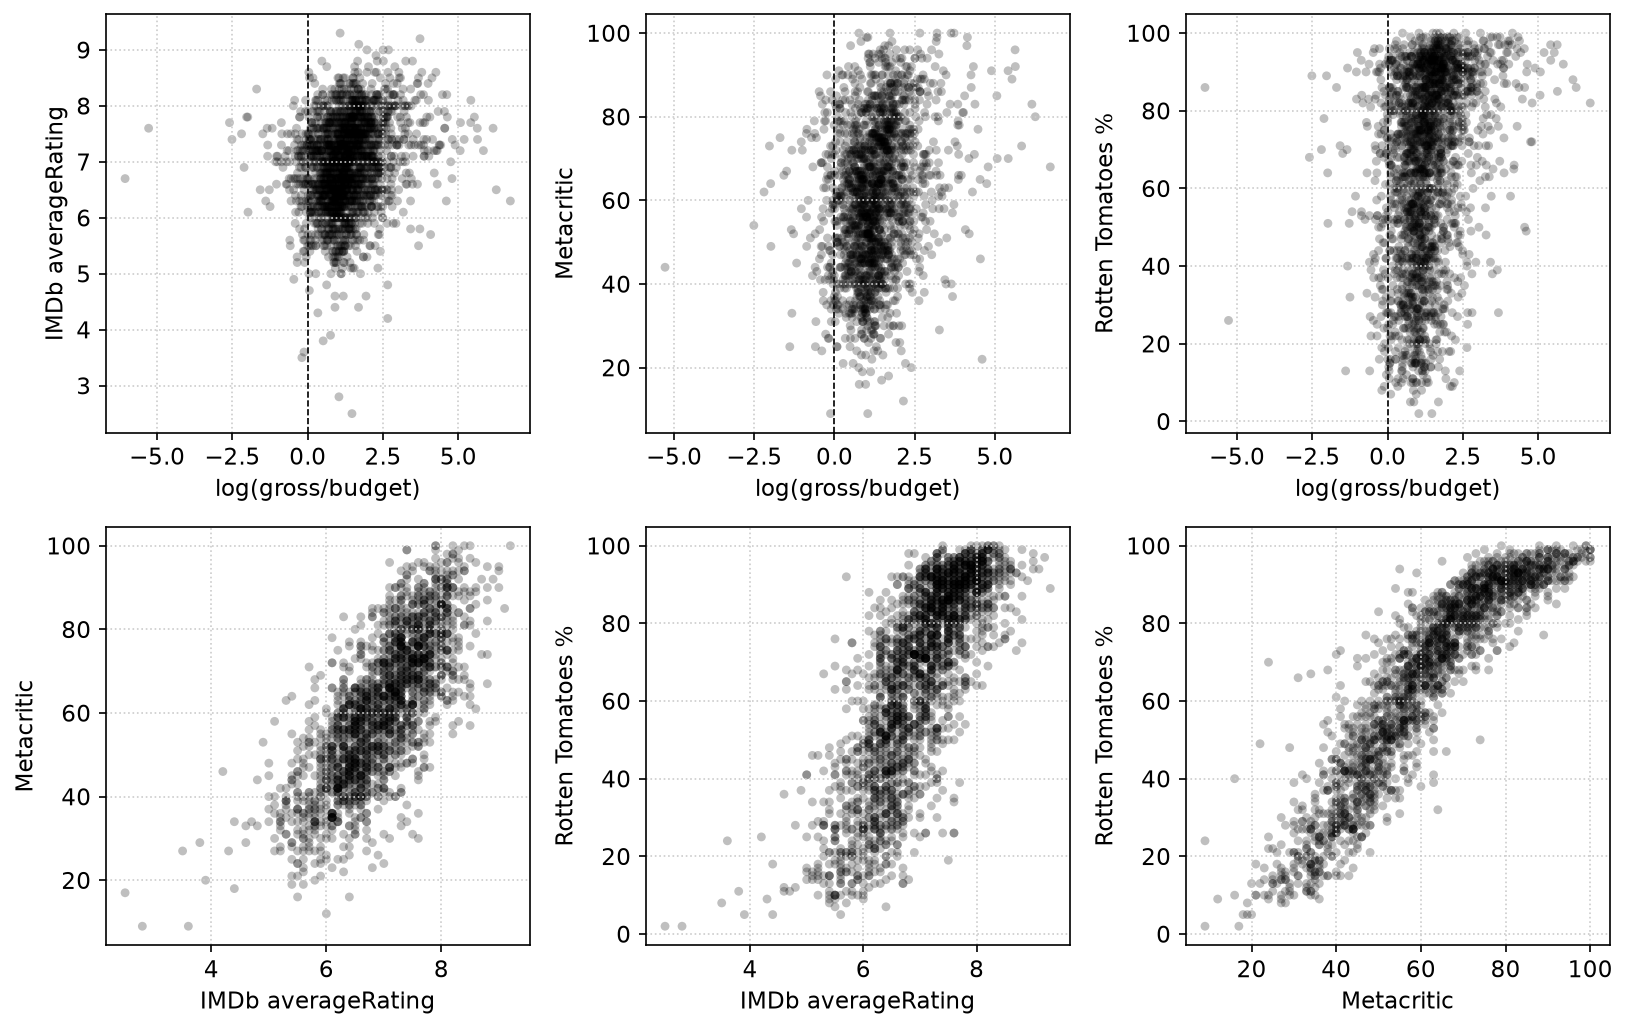

Figure. Quadrant view of money vs audience rating (100k+ clean, year ≤ 2017). Vertical dashed line: break-even; horizontal: median IMDb rating (7.00). Squares mark extreme disagreements (profitable + below-median rating, or unprofitable + above-median rating).


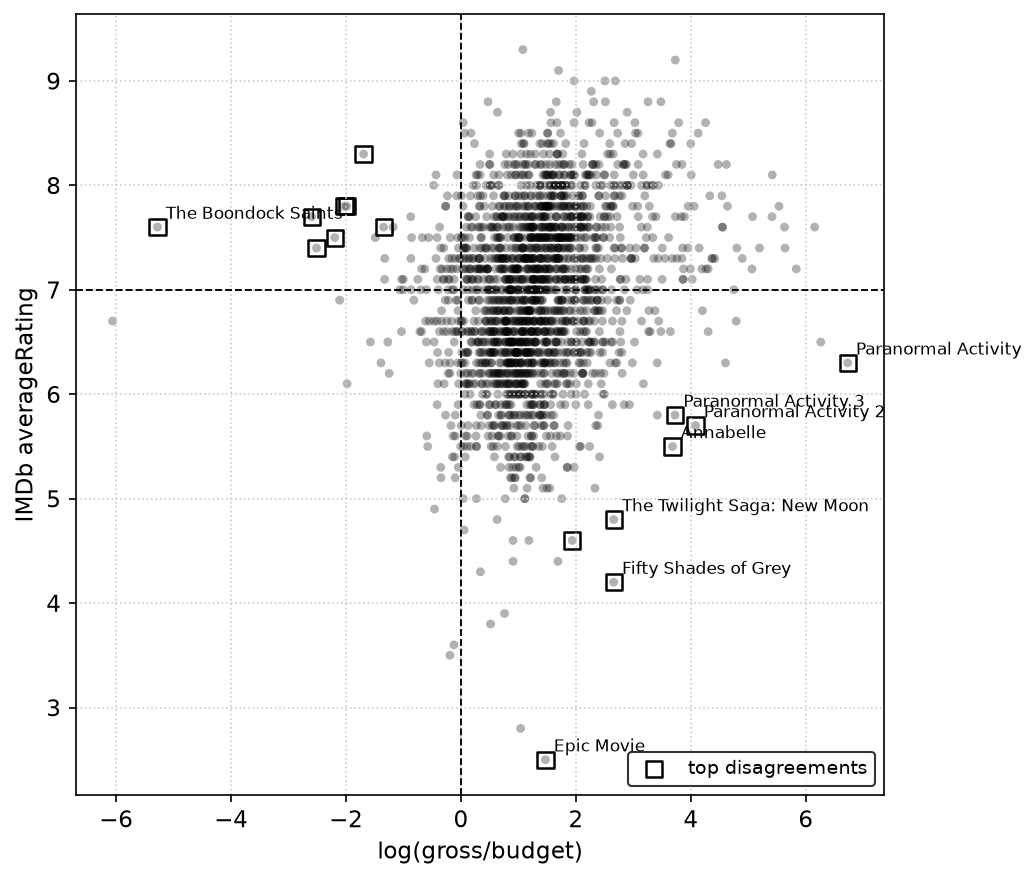

In [3]:
corr_path = OUTPUTS / "spearman_correlations.csv"
if not corr_path.exists():
    from analysis.reviews.run_exploration import idea1
    idea1(primary)

corr = pd.read_csv(corr_path)
display(corr.sort_values("rho", ascending=False))
print("\nWhat to read: rho is the observed Spearman; p_null is the fraction of")
print("label-shuffles with |rho_null| ≥ |rho| (plus-one correction).")

summary = pd.read_csv(OUTPUTS / "idea1_summary.csv", index_col=0)
display(summary)

for fig in ["fig_scatter_money_scores.png", "fig_quadrants_money_imdb.png"]:
    p = OUTPUTS / fig
    if p.exists():
        cap = p.with_suffix(".caption.txt")
        if cap.exists():
            display(Markdown(cap.read_text()))
        display(Image(filename=str(p)))

In [4]:
print("Top profitable but below-median IMDb rating")
display(pd.read_csv(OUTPUTS / "quadrant_profitable_low_imdb.csv").head(10))
print("Top loved (above-median IMDb) but unprofitable")
display(pd.read_csv(OUTPUTS / "quadrant_loved_unprofitable.csv").head(10))

print("\nSample bias (from data):")
print(f"  100k+ ≤{MAX_YEAR}: {len(primary)} movies, "
      f"{int(primary['under_budget'].sum())} under budget "
      f"({100*primary['under_budget'].mean():.1f}%).")
if len(optional):
    print(f"  Optional 10k Wikidata tier: {len(optional)} movies, "
          f"{int(optional['under_budget'].sum())} under budget "
          f"({100*optional['under_budget'].mean():.1f}%) — not hand-checked.")

Top profitable but below-median IMDb rating


,imdb_id,title,year,genres,log_gross_over_budget,gross_minus_budget,imdb_rating,metacritic,rotten_tomatoes,disagreement_score
0,tt2322441,Fifty Shades of Grey,2015,"Drama,Romance,Thriller",2.656230,529700000.0,4.2,46.0,25.0,7.437445
1,tt0799949,Epic Movie,2007,"Adventure,Comedy,Fantasy",1.469026,66900000.0,2.5,17.0,2.0,6.610616
2,tt1259571,The Twilight Saga: New Moon,2009,"Adventure,Drama,Fantasy",2.656055,662000000.0,4.8,44.0,28.0,5.843321
3,tt3322940,Annabelle,2014,"Horror,Mystery,Thriller",3.679606,251100000.0,5.5,37.0,28.0,5.519409
4,tt1536044,Paranormal Activity 2,2010,"Horror,Mystery",4.080358,174500000.0,5.7,53.0,58.0,5.304466
5,tt1179904,Paranormal Activity,2007,"Horror,Mystery",6.727754,193967500.0,6.3,68.0,82.0,4.709428
6,tt4465564,Fifty Shades Darker,2017,"Drama,Mystery,Romance",1.935466,326000000.0,4.6,33.0,11.0,4.645119
7,tt1778304,Paranormal Activity 3,2011,"Horror,Mystery,Thriller",3.723281,202000000.0,5.8,59.0,67.0,4.467937
8,tt1325004,The Twilight Saga: Eclipse,2010,"Action,Adventure,Drama",2.330143,631000000.0,5.1,58.0,46.0,4.427272
9,tt1333125,Movie 43,2013,Comedy,1.686399,26400000.0,4.4,18.0,5.0,4.384637


Top loved (above-median IMDb) but unprofitable


,imdb_id,title,year,genres,log_gross_over_budget,gross_minus_budget,imdb_rating,metacritic,rotten_tomatoes,disagreement_score
0,tt0144117,The Boondock Saints,1999,"Action,Crime,Thriller",-5.282739,-5969529.0,7.6,44.0,26.0,3.169644
1,tt0087843,Once Upon a Time in America,1984,"Crime,Drama",-1.696449,-24500000.0,8.3,75.0,86.0,2.205384
2,tt0485947,Mr. Nobody,2009,"Drama,Fantasy,Romance",-2.597385,-43500000.0,7.7,NaN,68.0,1.818169
3,tt0085794,The King of Comedy,1982,"Comedy,Crime,Drama",-2.028148,-16500000.0,7.8,73.0,89.0,1.622519
4,tt0460791,The Fall,2006,"Adventure,Drama,Fantasy",-1.990210,-25900000.0,7.8,64.0,64.0,1.592168
5,tt0112817,Dead Man,1995,"Adventure,Drama,Western",-2.197225,-8000000.0,7.5,62.0,70.0,1.098612
6,tt0103873,Braindead,1992,"Comedy,Fantasy,Horror",-2.514859,-2757377.0,7.4,54.0,89.0,1.005944
7,tt0116922,Lost Highway,1997,"Drama,Mystery,Thriller",-1.347074,-11100000.0,7.6,53.0,70.0,0.808244
8,tt0383028,"Synecdoche, New York",2008,Drama,-1.491655,-15500000.0,7.5,67.0,69.0,0.745827
9,tt0817177,Flipped,2010,"Comedy,Drama,Romance",-1.180442,-9700000.0,7.6,45.0,54.0,0.708265



Sample bias (from data):
  100k+ ≤2017: 2095 movies, 130 under budget (6.2%).
  Optional 10k Wikidata tier: 1126 movies, 366 under budget (32.5%) — not hand-checked.


## Text features from Tag Genome reviews

**Measures.** Mean review length (tokens); **lexical diversity as type–token ratio on fixed-size samples** (100 tokens) so longer reviews do not inflate diversity; **VADER** compound sentiment aggregated per movie, compared by genre.

**Misses.** VADER is a general lexicon (social-media trained), not a movie critic model. Tag Genome has no star rating or review date. Short reviews (<100 tokens) drop out of the diversity estimate.

**Checks.** (1) Label-shuffle nulls for sentiment/diversity vs money. (2) Export 50 random reviews for hand labelling. (3) Automatic VADER check against Stanford Large Movie Review gold labels (different corpus — transfer check only).

In [5]:
needed = [
    "genre_text_features.csv",
    "text_feature_spearman.csv",
    "sentiment_validation.json",
    "fig_text_features_genre.png",
]
if not all((OUTPUTS / f).exists() for f in needed):
    from analysis.reviews.run_exploration import text_block
    text_block(primary)

display(pd.read_csv(OUTPUTS / "genre_text_features.csv").head(15))
display(pd.read_csv(OUTPUTS / "text_feature_spearman.csv", index_col=0))
val = json.loads((OUTPUTS / "sentiment_validation.json").read_text())
print("Hand-label status:", val["hand_label"])
print("VADER vs Stanford (automatic):", val["stanford_vader"])
print("Hand-label CSV (gitignored text):", HAND_LABEL_CSV)
print("Template without text (committed):", HAND_LABEL_TEMPLATE)

cap = OUTPUTS / "fig_text_features_genre.caption.txt"
if cap.exists():
    display(Markdown(cap.read_text()))
display(Image(filename=str(OUTPUTS / "fig_text_features_genre.png")))

ModuleNotFoundError: No module named 'vaderSentiment'

## Idea 2 (exploratory) — critic vs audience language

**Measures.** Term rates per 10 000 words in Wikipedia reception text vs Tag Genome audience reviews (log–log scatter). Points near the diagonal are shared vocabulary; off-diagonal terms are side-specific.

**Misses.** Reception pages mix critic quotes with encyclopedic prose. Name removal is heuristic (titles + starring tokens), not full NER. Min frequency truncates rare but distinctive words.

**Inspect.** Top divergent terms are listed; short windows are written only under `build/` (private) for reading, not committed.

In [ ]:
if not (OUTPUTS / "fig_scattertext_critic_audience.png").exists():
    from analysis.reviews.run_exploration import idea2
    idea2(primary)

cov2 = pd.read_csv(OUTPUTS / "scattertext_coverage.csv", index_col=0)
display(cov2)
div = pd.read_csv(OUTPUTS / "scattertext_top_divergent_terms.csv")
display(div.head(15))
cap = OUTPUTS / "fig_scattertext_critic_audience.caption.txt"
if cap.exists():
    display(Markdown(cap.read_text()))
display(Image(filename=str(OUTPUTS / "fig_scattertext_critic_audience.png")))

## Optional extension: 10k–100k tier

**Measures.** Same profit proxy using **Wikidata** USD budget/gross for movies with 10k–99 999 votes (more flops).

**Misses.** Not hand-checked against Wikipedia; critic text / Metacritic often missing; treat as sensitivity check only.

In [ ]:
from analysis.reviews.nulls import spearman_with_null

if len(optional):
    ext = optional[optional["year"] <= MAX_YEAR]
    print("optional ≤2017:", len(ext),
          "under budget:", int(ext["under_budget"].sum()),
          f"({100*ext['under_budget'].mean():.1f}%)")
    res = spearman_with_null(ext["log_gross_over_budget"], ext["imdb_rating"], n_perm=1000)
    print("Spearman log(gross/budget) vs IMDb (10k optional):", res)
else:
    print("No optional rows.")

## Re-run

From the repo root (after `scripts/get_data.py --data-dir build/imdb` has genome + wiki features):

```bash
PYTHONPATH=. .venv/bin/python -m analysis.reviews.run_exploration
```

Then re-open this notebook. Fill `human_label` in the private hand-label CSV and re-run the sentiment validation cell / `agreement_from_hand_labels()`.